<a href="https://colab.research.google.com/github/Vishal-Mungal/NNDLPRACTICAL/blob/main/NNDL_MSPA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Generate Synthetic Training Data
To train our object detection network, we will programmatically generate random placements of our `cat.jpg` over random backgrounds, automatically keeping track of the true bounding boxes.

In [20]:
!pip install -q tensorflow opencv-python matplotlib
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [15]:
from google.colab import files
import os

uploaded = files.upload()

Saving image.jpg to image.jpg


In [16]:
image_path = next(iter(uploaded.keys()))

print("Image uploaded successfully:", image_path)

Image uploaded successfully: image.jpg


In [18]:
!pip install -q ultralytics
from ultralytics import YOLO

# Load pretrained CNN-based object detection model
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 7.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv8 model loaded successfully!


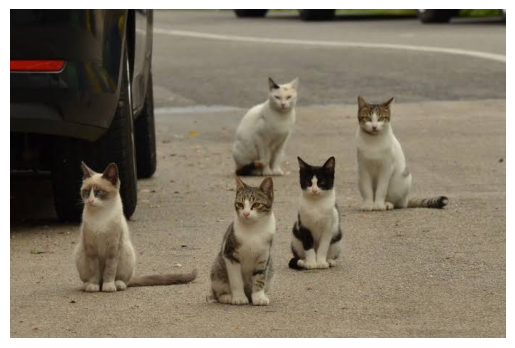

In [21]:
image = cv2.imread("image.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.axis("off")
plt.show()

In [22]:
model = tf.saved_model.load(
    tf.keras.utils.get_file(
        fname='ssd_mobilenet_v2',
        origin='https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2?tf-hub-format=compressed',
        untar=True
    )
)

23313757/23313757 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [24]:
detections=model(input_tensor)

In [26]:
print(detections.keys())

dict_keys(['detection_multiclass_scores', 'num_detections', 'detection_scores', 'detection_anchor_indices', 'detection_boxes', 'raw_detection_boxes', 'raw_detection_scores', 'detection_classes'])


In [25]:
# Preprocess the uploaded image
img_raw = cv2.imread('image.jpg')
img_rgb = cv2.cvtColor(img_raw, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_rgb, (320, 320))  # Standard SSD MobileNet size
input_tensor = tf.convert_to_tensor(img_resized)
input_tensor = input_tensor[tf.newaxis, ...]  # Add batch dimension

# Run the object detection model
detector_output = model(input_tensor)

# Extract detections (the model output is a dictionary of tensors)
detections = {key: value for key, value in detector_output.items()}

# Now we can safely extract boxes, classes, and scores
boxes = detections["detection_boxes"][0].numpy()
classes = detections["detection_classes"][0].numpy().astype(int)
scores = detections["detection_scores"][0].numpy()

print("Detections successfully processed!")

Detections successfully processed!


In [27]:
class_names = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "motorcycle",
    5: "bus",
    6: "traffic light",
    7: "stop sign",
    8: "parking meter",
    9: "bench",
    10: "bird",
    11: "dog",
    12: "elephant",
}

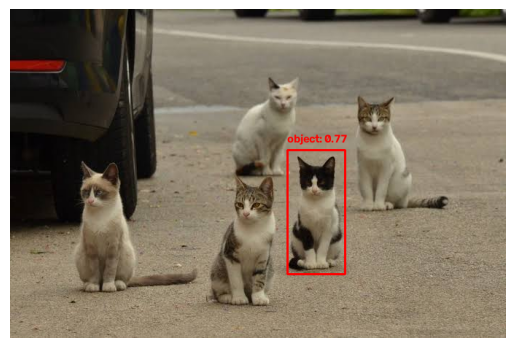

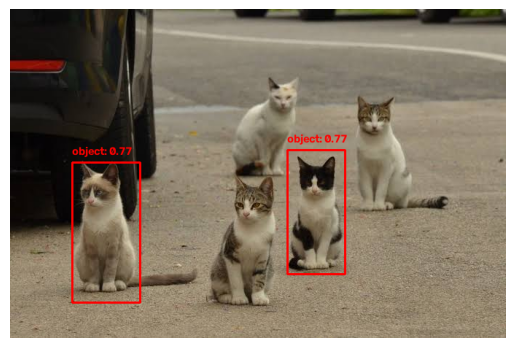

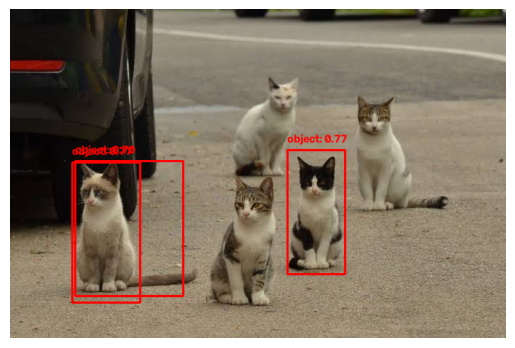

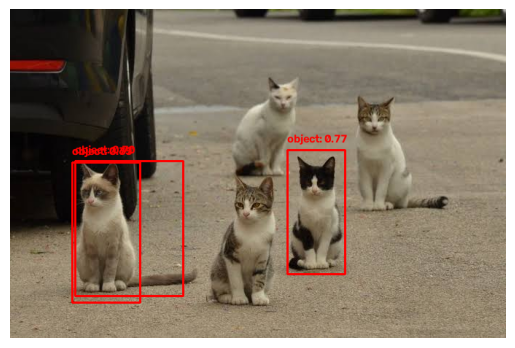

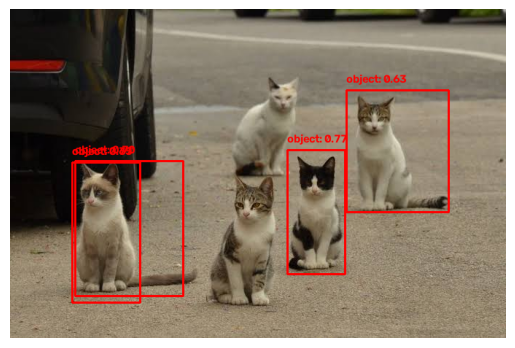

In [28]:
image_copy=image.copy()
height,width,_ = image_copy.shape
for i in range(5):
  if scores[i] > 0.5:
    ymin, xmin, ymax, xmax = boxes[i]

    start_point = (int(xmin * width), int(ymin * height))
    end_point = (int(xmax * width), int(ymax * height))

    cv2.rectangle(image_copy, start_point, end_point, (255, 0, 0), 2)
    label = class_names.get(classes[i], "object")
    confidence = scores[i]
    text = f"{label}: {confidence:.2f}"
    cv2.putText(image_copy, text, (start_point[0], start_point[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    plt.imshow(image_copy)
    plt.axis("off")
    plt.show()




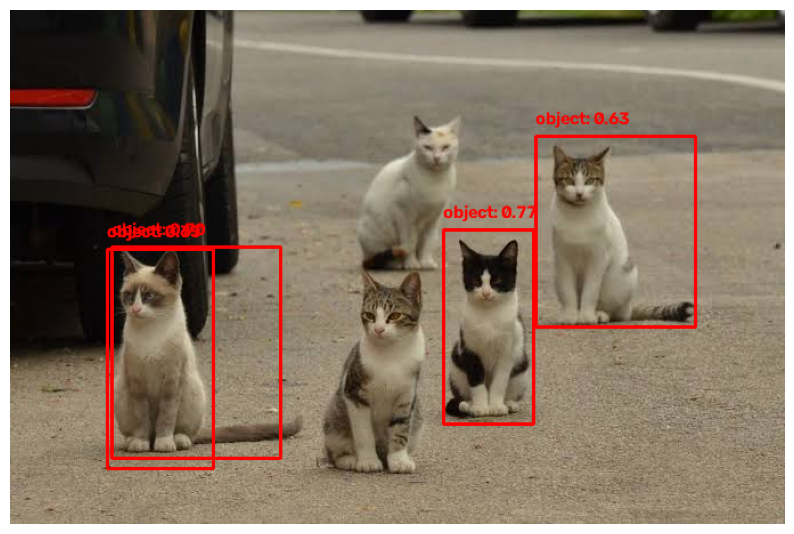

In [29]:
plt.figure(figsize=(10, 9))
plt.imshow(image_copy)
plt.axis("off")
plt.show()